# Multi-Class Benchmark Classification Pipeline (Iris)
Logistic Regression vs. Decision Tree with StandardScaler, an 80/20 split, classification reports, confusion-matrix heatmaps, and decision boundaries.

## 1. Load the dataset

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

sns.set_theme(style='whitegrid')
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
print(df.shape)
print(df.isna().sum().sum(), 'missing values')
df.head()

(150, 6)
0 missing values


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 2. Exploratory pairplot

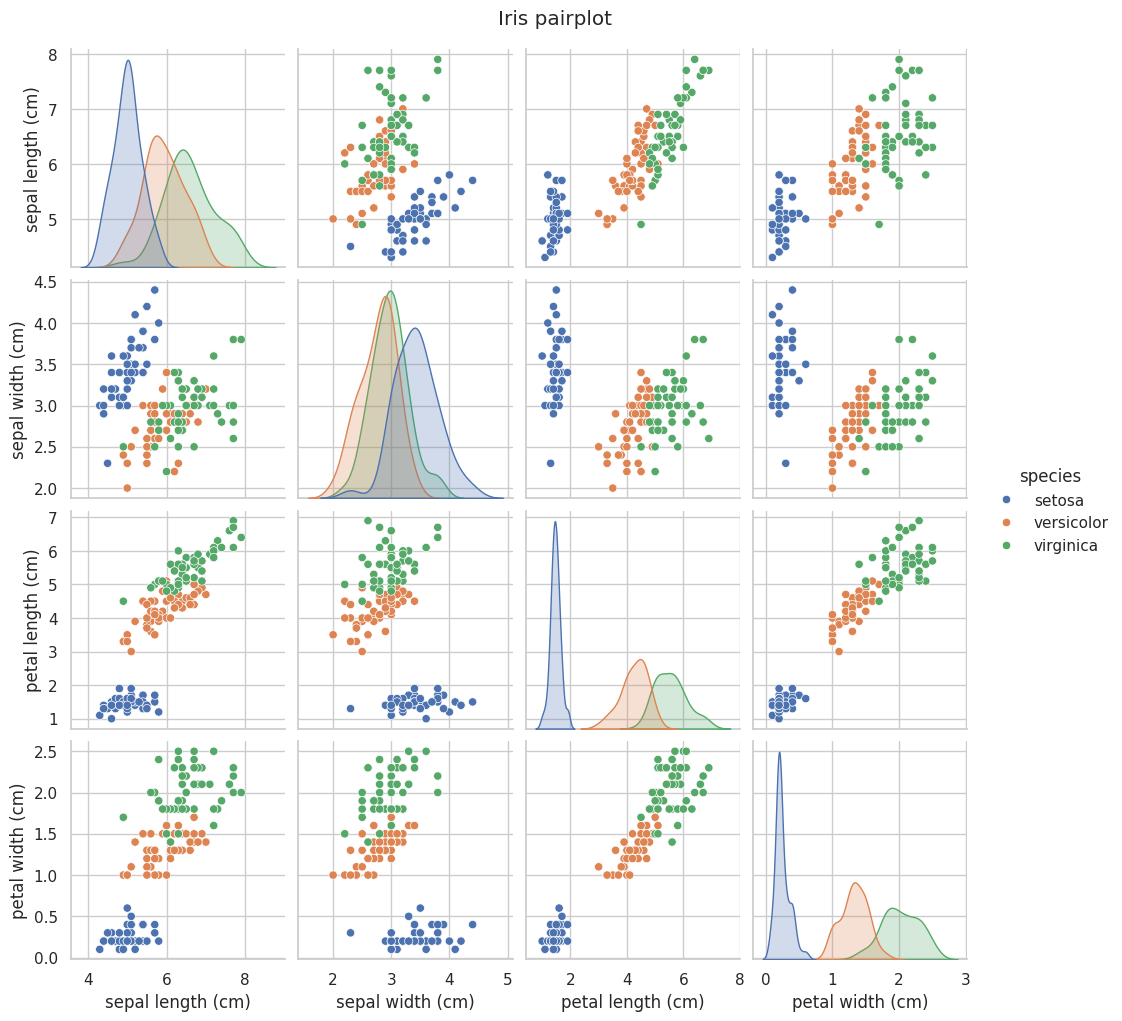

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [2]:
sns.pairplot(df.drop(columns='target'), hue='species', diag_kind='kde', corner=False)
plt.suptitle('Iris pairplot', y=1.02)
plt.show()
df.drop(columns=['target','species']).describe().round(2)

## 3. Split (80/20, stratified) and scale
The scaler is fit on the training set only, to avoid data leakage.

In [3]:
X = iris.data
y = iris.target
class_names = iris.target_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(120, 4) (30, 4)


## 4. Train models

In [4]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=42),
}
preds = {}
for name, m in models.items():
    m.fit(X_train_s, y_train)
    preds[name] = m.predict(X_test_s)
    print(f'===== {name} =====')
    print(classification_report(y_test, preds[name], target_names=class_names))

===== Logistic Regression =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

===== Decision Tree =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## 5. Benchmark comparison (macro-averaged)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


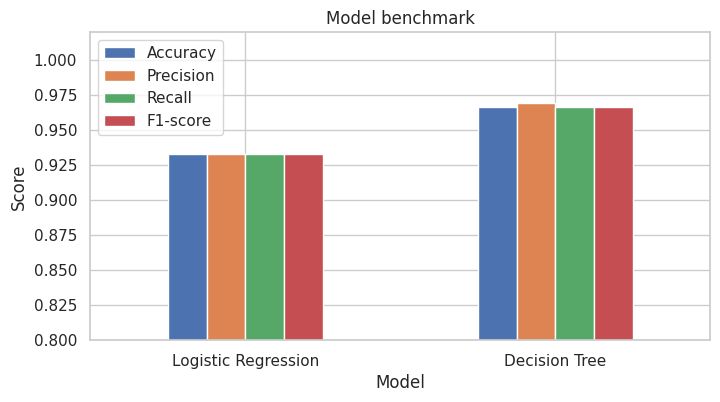

In [5]:
rows = []
for name, p in preds.items():
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, p),
                 'Precision': precision_score(y_test, p, average='macro'),
                 'Recall': recall_score(y_test, p, average='macro'),
                 'F1-score': f1_score(y_test, p, average='macro')})
results = pd.DataFrame(rows).set_index('Model').round(4)
display(results)
results.plot(kind='bar', figsize=(8,4), ylim=(0.8,1.02), rot=0)
plt.title('Model benchmark'); plt.ylabel('Score'); plt.show()

## 6. Confusion matrix heatmaps

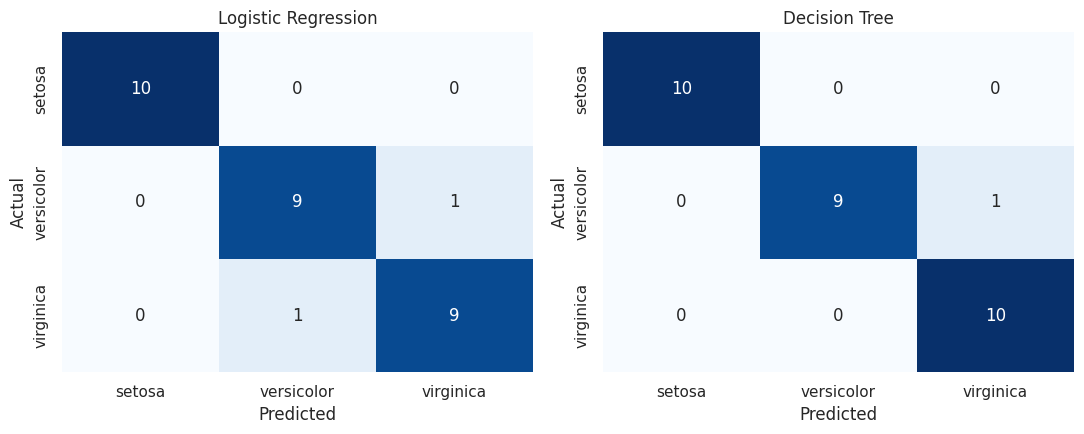

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 7. Decision boundary visualization
Decision boundaries need 2 dimensions, so the scaled features are projected with PCA and both models are refit on the 2D projection (used for visualization only).

Variance explained by 2 PCs: 0.957


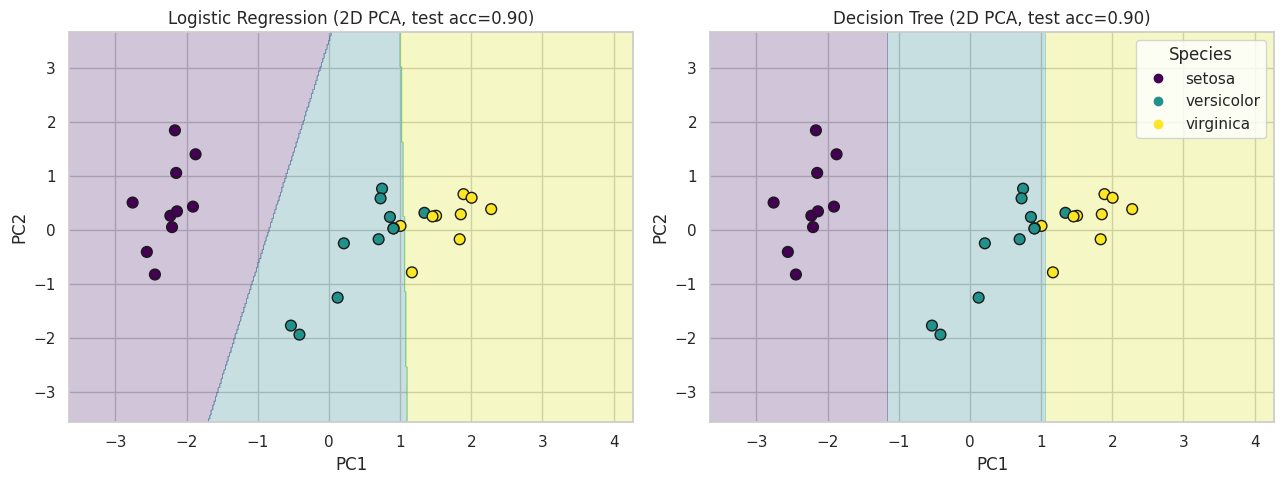

In [7]:
pca = PCA(n_components=2, random_state=42)
Xtr2 = pca.fit_transform(X_train_s)
Xte2 = pca.transform(X_test_s)
print('Variance explained by 2 PCs:', pca.explained_variance_ratio_.sum().round(3))

xx, yy = np.meshgrid(
    np.linspace(Xtr2[:,0].min()-1, Xtr2[:,0].max()+1, 400),
    np.linspace(Xtr2[:,1].min()-1, Xtr2[:,1].max()+1, 400))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(13,5))
for ax, (name, m) in zip(axes, {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
        'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=42)}.items()):
    m.fit(Xtr2, y_train)
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap='viridis')
    sc = ax.scatter(Xte2[:,0], Xte2[:,1], c=y_test, cmap='viridis', edgecolor='k', s=60)
    acc = accuracy_score(y_test, m.predict(Xte2))
    ax.set_title(f'{name} (2D PCA, test acc={acc:.2f})')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
handles, _ = sc.legend_elements()
axes[1].legend(handles, class_names, title='Species')
plt.tight_layout(); plt.show()